# Relative motion about an eccentric chief: beyond Hill-Clohessy-Wiltshire

`cw_fundamentals.ipynb` builds everything on the Hill-Clohessy-Wiltshire equations, which assume the chief is on a circular orbit. Most real targets are not exactly circular, and this notebook extends the relative dynamics to a chief of arbitrary eccentricity with `eccentric_hill_equations_symbolic`, which propagates the chief's own absolute state alongside the deputy's relative one, so the chief's radius and angular rate drive the relative equations as they actually evolve rather than as the constants a circular chief would give. The relative motion itself is still linearized in the separation, exactly as in the circular case; only the assumption that the chief is circular is dropped.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH
from ios_mission_planner.dynamics.orbital.elements import ClassicalElements, cartesian_state_from_elements
from ios_mission_planner.dynamics.orbital.two_body import two_body_dynamics_symbolic
from ios_mission_planner.dynamics.relative.hill import hill_equations_symbolic
from ios_mission_planner.dynamics.relative.eccentric_hill import eccentric_hill_equations_symbolic
from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh, lvlh_to_inertial
from ios_mission_planner.dynamics.relative.relative_orbit import RelativeOrbit, state_from_relative_orbit
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## Reduction check: a circular chief must give back plain Hill

Before trusting the new model on an eccentric chief, the first and cheapest check is that it reproduces the already-validated circular Hill equations exactly when the chief happens to be circular.

In [2]:
a_c = R_EARTH + 500.0
v_circ = np.sqrt(MU_EARTH / a_c)
n_circ = np.sqrt(MU_EARTH / a_c**3)
chief0_circ = np.array([a_c, 0.0, 0.0, 0.0, v_circ, 0.0])
rel0 = np.array([50.0, -200.0, 30.0, 0.01, -0.02, 0.005])

t_eval = np.linspace(0.0, 1.5 * 2 * np.pi / n_circ, 400)

state0 = np.concatenate([chief0_circ, rel0])
rel_general = propagate(eccentric_hill_equations_symbolic(), state0, t_eval, pars=[MU_EARTH]).y[6:, :]
rel_circular = propagate(hill_equations_symbolic(), rel0, t_eval, pars=[n_circ]).y

print(f"max difference from the circular-chief model: {np.abs(rel_general - rel_circular).max():.2e} km")

max difference from the circular-chief model: 1.32e-11 km


## Validating the linearization against the nonlinear truth

For an eccentric chief, the honest check is against the fully nonlinear truth: propagate chief and deputy separately with plain two-body dynamics, convert both to the chief's LVLH frame at every instant with `inertial_to_lvlh`, and compare that to the linearized model started from the same relative state. This isolates exactly the approximation being made, linearizing the relative acceleration in the separation, with nothing else in the way.

max error: 0.192 m (0.173% of separation)


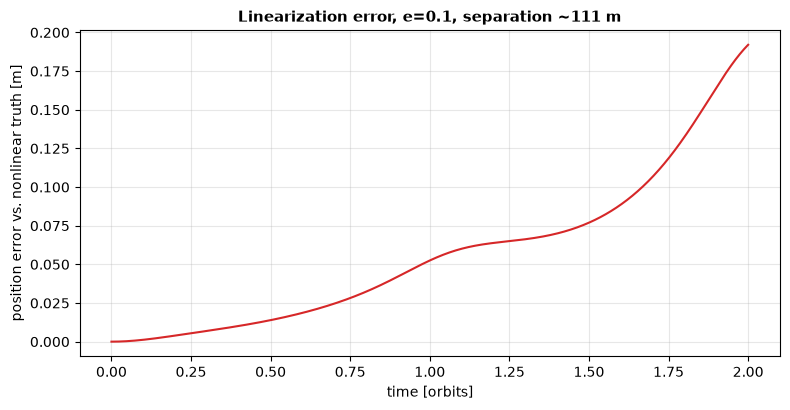

In [3]:
chief_el = ClassicalElements(a=R_EARTH + 500.0, e=0.1, i=np.deg2rad(30.0), raan=0.2, argp=0.5, mean_anomaly=0.0)
chief0 = cartesian_state_from_elements(chief_el, MU_EARTH)
n0 = np.sqrt(MU_EARTH / chief_el.a**3)
period = 2 * np.pi / n0

# a small, drift-free (in the CW sense) relative orbit, ~110 m
orbit = RelativeOrbit(x_off=0.0, y_c=0.0, rho=0.1, alpha=0.0, rho_z=0.05, beta=0.3)
rel0_small = state_from_relative_orbit(orbit, n0)
deputy0 = lvlh_to_inertial(chief0, rel0_small)

t_eval = np.linspace(0.0, 2 * period, 600)

sol_c = propagate(two_body_dynamics_symbolic(), chief0, t_eval, pars=[MU_EARTH]).y
sol_d = propagate(two_body_dynamics_symbolic(), deputy0, t_eval, pars=[MU_EARTH]).y
rel_truth = np.array([inertial_to_lvlh(sol_c[:, i], sol_d[:, i]) for i in range(len(t_eval))]).T

state0 = np.concatenate([chief0, rel0_small])
rel_lin = propagate(eccentric_hill_equations_symbolic(), state0, t_eval, pars=[MU_EARTH]).y[6:, :]

pos_error_m = np.linalg.norm(rel_lin[:3, :] - rel_truth[:3, :], axis=0) * 1e3
separation_m = np.linalg.norm(rel0_small[:3]) * 1e3

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(t_eval / period, pos_error_m, color=COL_NUM)
ax.set_xlabel("time [orbits]")
ax.set_ylabel("position error vs. nonlinear truth [m]")
ax.set_title(f"Linearization error, e={chief_el.e}, separation ~{separation_m:.0f} m")
fig.tight_layout()

print(f"max error: {pos_error_m.max():.3f} m ({100 * pos_error_m.max() / separation_m:.3f}% of separation)")

The error stays a small fraction of the separation itself over two full orbits, consistent with what a linearization in the separation should give for a target this close to the chief; it is not exactly zero, since the chief is genuinely eccentric here and the comparison is against the full nonlinear two-body truth, but it is the kind of small, expected residual rather than a sign of a wrong model.

## What chief eccentricity does to a "drift-free" design

`cw_fundamentals.ipynb` designs a drift-free relative orbit by setting `x_off = 0`; for a circular chief that orbit closes on itself exactly, orbit after orbit. The chief's radius and angular rate are no longer constant once the chief is eccentric, so that same construction, built from the circular-chief formulas, is no longer exactly periodic: it was tuned to a constant angular rate that the chief no longer has. Propagating the identical initial relative state against both models side by side over several orbits shows exactly this.

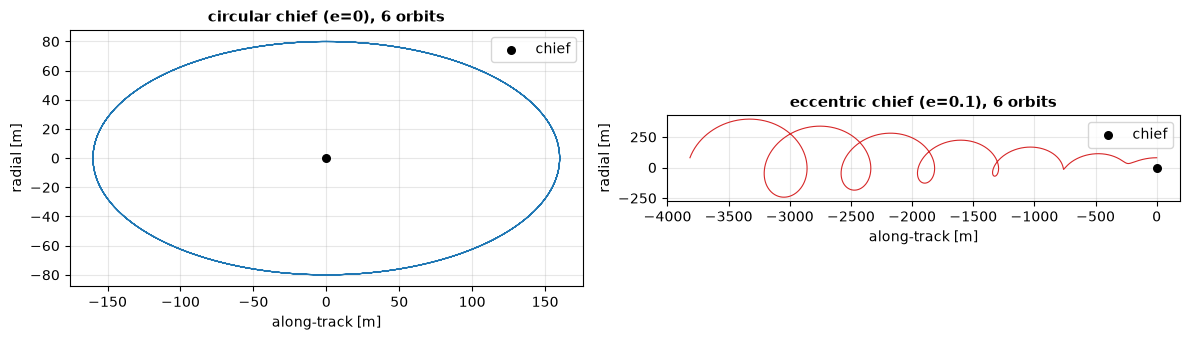

In [4]:
orbit_design = RelativeOrbit(x_off=0.0, y_c=0.0, rho=0.08, alpha=0.0, rho_z=0.0, beta=0.0)

n_orbits = 6
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))

for ax, (label, chief0_case, n_case, color) in zip(axes, [
    ("circular chief (e=0)", chief0_circ, n_circ, COL_ANA),
    (f"eccentric chief (e={chief_el.e})", chief0, n0, COL_NUM),
]):
    rel0_case = state_from_relative_orbit(orbit_design, n_case)
    t_eval_case = np.linspace(0.0, n_orbits * (2 * np.pi / n_case), 3000)
    state0_case = np.concatenate([chief0_case, rel0_case])
    rel_case = propagate(eccentric_hill_equations_symbolic(), state0_case, t_eval_case, pars=[MU_EARTH]).y[6:, :]

    ax.plot(rel_case[1, :] * 1e3, rel_case[0, :] * 1e3, color=color, lw=0.8)
    ax.scatter([0], [0], color="k", s=30, zorder=5, label="chief")
    ax.set_xlabel("along-track [m]"); ax.set_ylabel("radial [m]")
    ax.set_title(f"{label}, {n_orbits} orbits")
    ax.set_aspect("equal")
    ax.legend()

fig.tight_layout()

The circular-chief case traces the same closed 2:1 ellipse every orbit, exactly as `cw_fundamentals.ipynb` shows. The eccentric-chief case, built from the identical design formula and the identical initial separation, visibly fails to close: each pass through the ellipse is shifted from the last. The lesson is general: a relative orbit designed drift-free against one dynamical model is only as drift-free as that model's own assumptions. Chief eccentricity is one such assumption; the oblateness of the Earth, the subject of the next notebook, is another, and both are worth checking before trusting a design to stay put.

## Summary

`eccentric_hill_equations_symbolic` extends the relative dynamics to a chief of any eccentricity by propagating the chief's own state alongside the deputy's relative one, rather than assuming a constant angular rate. It reduces to the circular Hill equations exactly when the chief is circular, matches the fully nonlinear two-body truth to a fraction of a percent for a realistically small, close relative orbit, and shows directly that a relative orbit designed to be drift-free against a circular-chief assumption is not actually drift-free once the chief is even mildly eccentric. This is a linearization in the separation only, same as the circular case; it says nothing about J2 or any other perturbation, which is the subject of the next notebook, `j2_roe_state_transition.ipynb`.